In [1]:
%load_ext autoreload
%autoreload 2

%load_ext sql
%sql duckdb:///:memory:

%sql create or replace view V_SERIATIM as select * from read_parquet('../../mort_data/V_SERIATIM.parquet')
%sql create or replace view V_GROUP_RESPONSE as select * from read_parquet('../../mort_data/V_GROUP_RESPONSE.parquet')

import sys
sys.path.insert(0, "../../")

import formulaic as frm, pandas as pd, numpy as np


The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

Connecting to 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

# Individual Models from Grouped Data

Working with grouped response data and individual level predictors is an unusual problem.  Fortunately, the same simple math that applies to deep-learning and many other complex machine learning problems also applies here.  We can make use of the **chain rule** from calculus to estimate individual level predictions, even though our claims are aggregated to the group level.

Here is how it works in a nutshell:

 * The group's claims are just the sum of the individual claims:  
 
 $$
 \text{Group Claims}_i = \sum_j \text{individual claims}_{i,j}
 $$

* We can (theoretically) predict individual claims using a GLM model (with INDIVIDUAL exposures / offsets) IF we know the $\beta$'s.

$$
\text{individual claims} = \text{policies exposed} \times \exp \big[ \beta_0 + \beta_1 \times \text{age} + \beta_1 \times \text{gender} \big]
$$

* so we just need to solve the equation (for the $\beta$'s).  Hard for humans, but easy for computers!

 $$
 \sum \text{Group Claims} = \sum \bigg[ \text{policies exposed} \times \exp \big[ \beta_0 + \beta_1 \times \text{age} + \beta_1 \times \text{gender} \big] \bigg]
 $$

* Since this is a smooth function when we apply Poisson Likelihood, we can use any smooth function optimizer (there are many choices).  [L-BFGS](https://en.wikipedia.org/wiki/Limited-memory_BFGS) is usually a very powerful option, and it's bundled in [scipy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html).  Even better, we can apply monotonic constraints with it (e.g., only positive coefficients).



### 

### Simulated Group Data

The data is drawn randomly from the ILEC dataset.  It's seriatim-ish in many places.  We can simulate groups by first choosing a group size, and then assigning the cell to that group in that year.  Maybe trust me that I've thought this through enough that this magic trick we're about to see isn't a mirage.

Here are the group sizes in the training data:



Running query in 'duckdb:///:memory:'

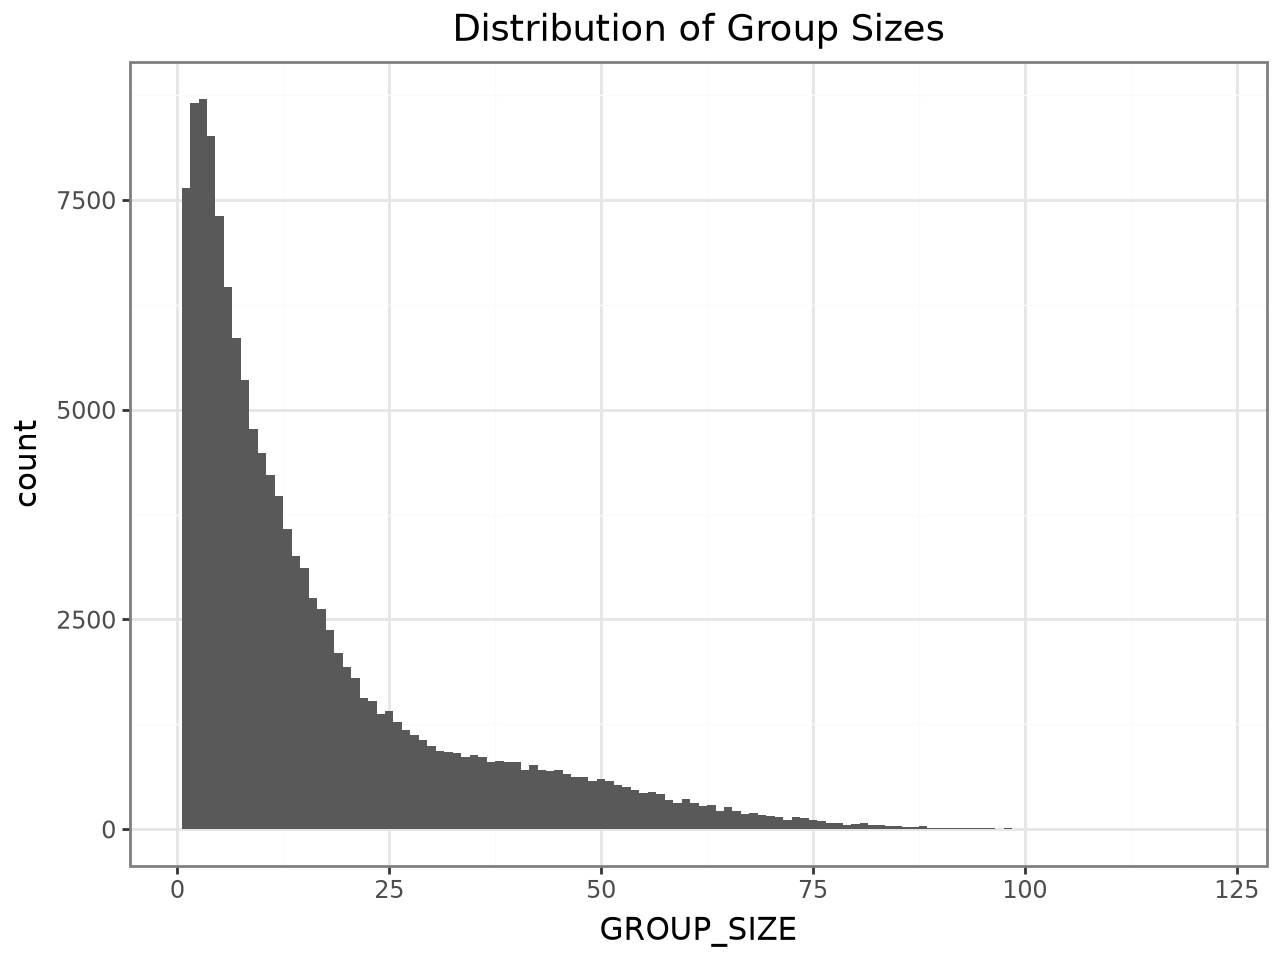

In [33]:
import plotnine as p9

df_group_sizes = %sql select GROUP_ID, count(1) as GROUP_SIZE from V_SERIATIM group by GROUP_ID
df_group_sizes = df_group_sizes.DataFrame()

(
    p9.ggplot(df_group_sizes, p9.aes(x="GROUP_SIZE"))
    + p9.geom_histogram(binwidth=1)
    + p9.theme_bw()
    + p9.labs(title="Distribution of Group Sizes")
)

### Experiment

We'll create simulated grouped data and fit an individual-level GLM to it.

 * Once you've run through this notebook, experiment with the GROUP_SIZE filter in the train / test split.

In [52]:
%%sql
-- performs the train / test split and any group size filtering
create or replace table V_TT_SPLIT as
with group_id as (    
    select distinct GROUP_ID, sum(POLICIES_EXPOSED) as GROUP_SIZE from V_SERIATIM
    group by GROUP_ID
)
select
    group_id.GROUP_ID,
    case when random() < 0.7 then 1 else 0 end as TRAIN_IND
from group_id
-- experiment w/ bigger groups, more pessimistic / loses more information  
where GROUP_SIZE > 10

Running query in 'duckdb:///:memory:'

Count


In [ ]:
%%sql
-- create the individual-level predictors.
-- there are NO actuals / claims values here, only predictors and expecteds
create or replace view V_MODEL_INDIVIDUAL_PREDICTORS as
select
    V.OBS_ID,
    V.OBSERVATION_YEAR,
    V.GROUP_ID,
    T.TRAIN_IND,
    V.ATTAINED_AGE,
    V.GENDER,
    -- our expecteds / exposures must be seriatim!
    V.POLICIES_EXPOSED
from V_SERIATIM V
 inner join V_TT_SPLIT T on V.GROUP_ID = T.GROUP_ID

Running query in 'duckdb:///:memory:'

Count


In [ ]:
%%sql
-- create the grouped (summed) claims for the individual groups
create or replace view V_MODEL_GROUP_RESPONSE as
with tt_split as (
    select distinct group_id, OBSERVATION_YEAR, train_ind 
    from V_MODEL_INDIVIDUAL_PREDICTORS
)
select  
    S.group_id,
    MAX(t.train_ind) as train_ind,
    SUM(S.CLAIM_COUNT) AS GROUP_CLAIM_COUNT
from V_SERIATIM S
 inner join V_TT_SPLIT t 
  on S.GROUP_ID = t.GROUP_ID
group by S.group_id


Running query in 'duckdb:///:memory:'

Count


### Begin Model Build

Note the difference in the number of rows in the below dataframe.  Unlike typical models, we have (far) fewer response rows than predictor rows.

In [47]:
# train / test splits are not as simple as 70 / 30. Usually, using future years of experience 
# for the test data is the best safeguard against overfit.
df_X_train = %sql select * from V_MODEL_INDIVIDUAL_PREDICTORS where TRAIN_IND = 1
df_X_test = %sql select * from V_MODEL_INDIVIDUAL_PREDICTORS where TRAIN_IND = 0

df_y_train = %sql select * from V_MODEL_GROUP_RESPONSE where TRAIN_IND = 1
df_y_test = %sql select * from V_MODEL_GROUP_RESPONSE where TRAIN_IND = 0

df_X_train, df_y_train, df_X_test, df_y_test = \
    df_X_train.DataFrame(), df_y_train.DataFrame(), df_X_test.DataFrame(), df_y_test.DataFrame()

df_row_counts = pd.DataFrame({
    "dataframe": ["df_X_train", "df_X_test", "df_y_train", "df_y_test"],
    "row_count": [len(df_X_train), len(df_X_test), len(df_y_train), len(df_y_test)]
})

print(f"Number of claims in train / test: {df_y_train['GROUP_CLAIM_COUNT'].sum()} / {df_y_test['GROUP_CLAIM_COUNT'].sum()}")

# note the differences in row counts between our predictors (X) and
# our response variables (y).  Predictors are individual-level (age and sex),
# while the response is the sum of claims / expecteds for a group.
df_row_counts

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

Number of claims in train / test: 46794.0 / 19890.0


,dataframe,row_count
0,df_X_train,1443666
1,df_X_test,616483
2,df_y_train,68581
3,df_y_test,29333


#### Note about LFBGS and traditional GLMs (not `glmnet` / `glum`)

Usually, model fitting fails when there are co-linear columns.  The real enemy is nearly-colinear columns.  `glmnet` and `glum` spoil us by taking care of these automatically, but we need to be careful about this (especially when using splines) when using other glm fitting algorithms

 * The below method `find_bad_design_columns()` uses a couple common linear algebra operations to look for problems.  It generally works well for simple to medium-complexity models.  It will take a very long time to run on complex models.

In [ ]:
from src.lib.grpmodels import find_bad_design_columns

# like the glmnet / glum model, we need to EXCLUDE an intercept (-1 at end).
# we are building the design matrix at an individual level.
X_mmat = frm.model_matrix(
    "cr(ATTAINED_AGE, knots=[30, 50, 60])*GENDER - 1",
    df_X_train)

# run some heuristics to see if any columns are sparse.
# Unlike GLMNET, we don't have any guards against (nearly) collinear columns.
# ALWAYS do this if using splines, and especially when doing splines w/ interactions.
# The model.matrix formula (w/ -1) also introduces a term that will be colinear with the intercept, so we need to remove it.  
bad_cols = find_bad_design_columns(X_mmat)

print(f"Found {len(bad_cols)} bad columns: {bad_cols}")

Found 3 bad columns: ['GENDER[FEMALE]', 'GENDER[MALE]', 'cr(ATTAINED_AGE, knots=[30, 50, 60])[4]']


In [53]:
from src.lib.grpmodels import GroupedPoissonGLM

# remember, we need to provide the exposure / offset at the individual level
X_fit_train = pd.concat([
     df_X_train[["GROUP_ID", "POLICIES_EXPOSED"]],
     X_mmat.drop(columns=bad_cols)
], axis=1)

# always take the log of the offset column
X_fit_train["log_POLICIES_EXPOSED"] = np.log(X_fit_train["POLICIES_EXPOSED"])

# define the model structure. GroupedPoissonGLM() has more parameters, but the
# defaults are usually fine.  maxiter is set to 10,000 to ensure convergence, 
# since we are using splines and interactions.
model = GroupedPoissonGLM(
    y_col="GROUP_CLAIM_COUNT", 
    offset_col="log_POLICIES_EXPOSED", 
    maxiter = 10_000)

# fit INDIVIDUAL level betas using a GROUPED response
model_fit = model.fit(
    X_fit_train, 
    df_y_train
)

# after fitting the model, run a sanity check to make sure
# that we are seeing 100% A/E with the model's predictions (checks convergence)
df_pred_grouped = (
    model_fit
    # we are prodiving group-level model predictions, we'll do individual next!
    .predict_group_mu(X_fit_train)
    .merge(df_y_train, how="inner", on="GROUP_ID")
)

# A/E sanity check for convergence (should be very close to 1)
df_pred_grouped["MODEL_PRED"] = df_pred_grouped["mu_group"] 
df_pred_grouped["GROUP_CLAIM_COUNT"].sum() / df_pred_grouped["MODEL_PRED"].sum()

np.float64(1.0000298399153074)

Running query in 'duckdb:///:memory:'

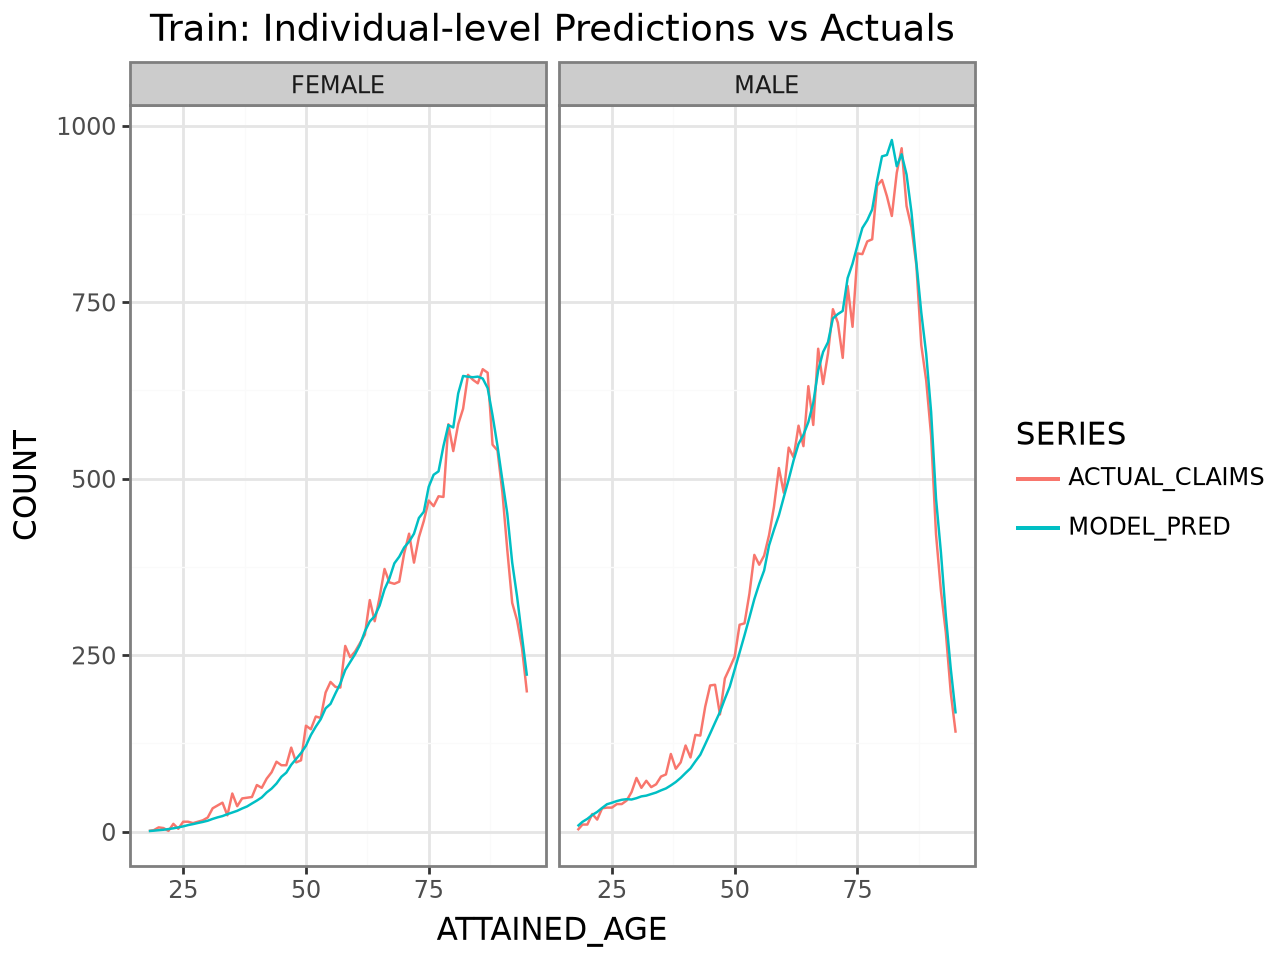

In [54]:
# let's get the ACTUAL individual claims (unseen by model)
df_check_train_preds = %sql select V.* from V_SERIATIM V inner join V_TT_SPLIT T on V.GROUP_ID = T.GROUP_ID where T.TRAIN_IND = 1
df_check_train_preds = df_check_train_preds.DataFrame()

# ALWAYS reuse the model_matrix / model_spec from fitting.
# DON'T recreate the model matrix with a string when using splines
model_spec = X_mmat.model_spec

# calculate design matrix. 
X_check_train_preds = pd.concat([
     df_check_train_preds[["GROUP_ID", "POLICIES_EXPOSED"]],
     model_spec.get_model_matrix(df_check_train_preds).drop(columns=bad_cols)
], axis=1)

# remember to calculate the log of the offset column
X_check_train_preds["log_POLICIES_EXPOSED"] = np.log(X_check_train_preds["POLICIES_EXPOSED"])

# add individual model predictions to the individual-level data frame.  
df_check_train_preds["MODEL_PRED"] = model_fit.predict_individual_mu(X_check_train_preds)

# plotnine, like ggplot in R, is very opinioned about the shape of data that you give it,
# when plotting two series (actual claim counts vs. predicted claims counts), it's easiest
# to pivot the data into a long format (.melt())
df_plot_data = (
    df_check_train_preds
    .groupby(["ATTAINED_AGE", "GENDER"])
    .agg(
        ACTUAL_CLAIMS = pd.NamedAgg(column="CLAIM_COUNT", aggfunc="sum"),
        MODEL_PRED = pd.NamedAgg(column="MODEL_PRED", aggfunc="sum")
    )
    .reset_index()
    .melt(
        id_vars=["ATTAINED_AGE", "GENDER"],
        value_vars=["ACTUAL_CLAIMS", "MODEL_PRED"],
        var_name="SERIES",
        value_name="COUNT")
)

import plotnine as p9

(
    p9.ggplot(df_plot_data, p9.aes(x="ATTAINED_AGE", y="COUNT", color="SERIES"))
    + p9.geom_line()
    + p9.facet_wrap("~GENDER")
    + p9.theme_bw()
    + p9.labs(title="Train: Individual-level Predictions vs Actuals")
)


Running query in 'duckdb:///:memory:'

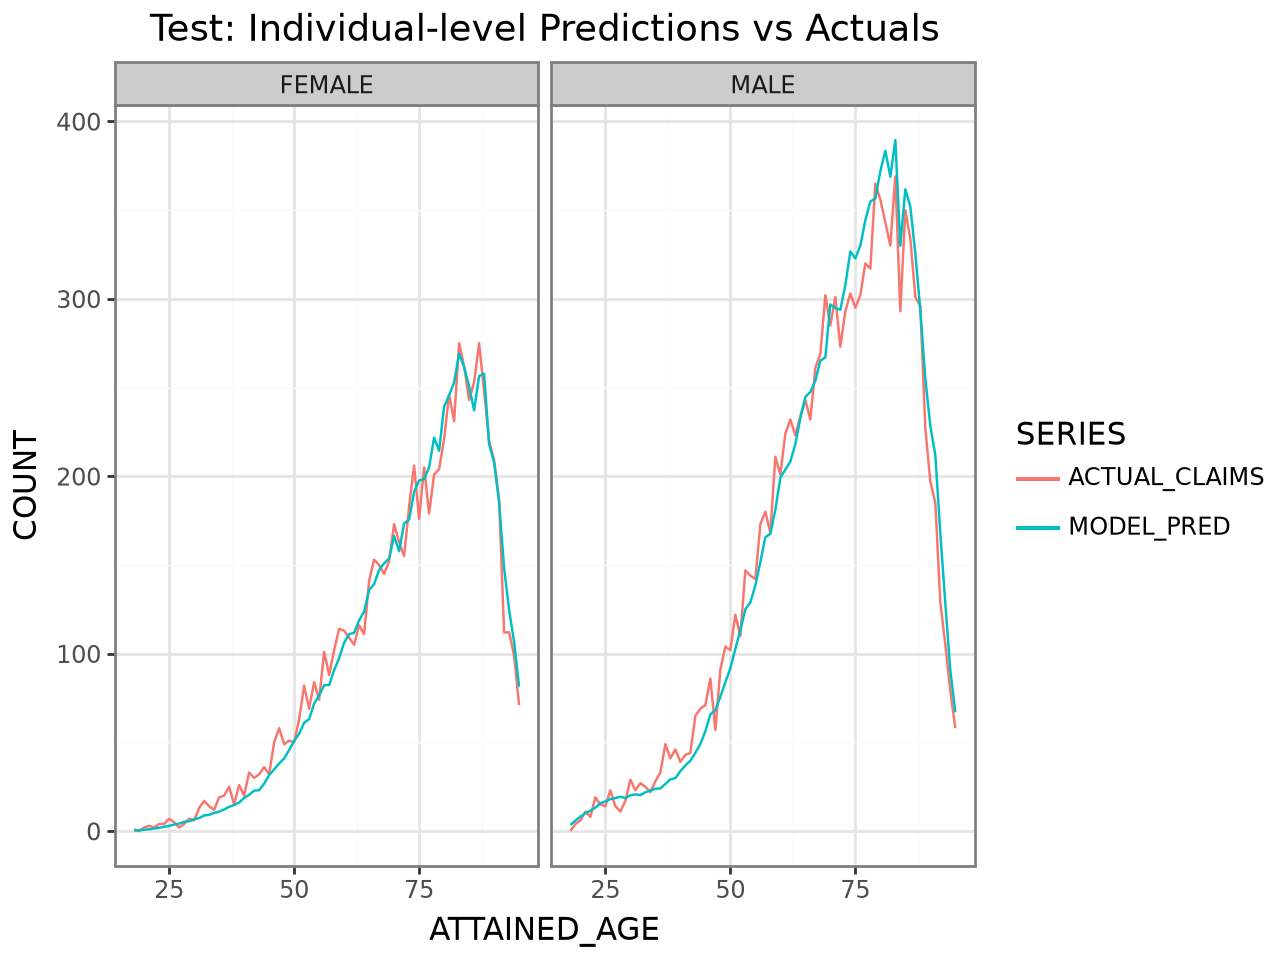

In [51]:
# let's get the OUT-OF-SAMPLE individual claims (unseen by model)
df_check_test_preds = %sql select V.* from V_SERIATIM V inner join V_TT_SPLIT T on V.GROUP_ID = T.GROUP_ID where T.TRAIN_IND = 0
df_check_test_preds = df_check_test_preds.DataFrame()

# ALWAYS reuse the model_matrix / model_spec from fitting.
# DON'T recreate the model matrix with a string when using splines
model_spec = X_mmat.model_spec

# calculate design matrix. 
X_check_test_preds = pd.concat([
     df_check_test_preds[["GROUP_ID", "POLICIES_EXPOSED"]],
     model_spec.get_model_matrix(df_check_test_preds).drop(columns=bad_cols)
], axis=1)

# remember to calculate the log of the offset column
X_check_test_preds["log_POLICIES_EXPOSED"] = np.log(X_check_test_preds["POLICIES_EXPOSED"])

# add individual model predictions to the individual-level data frame.  
df_check_test_preds["MODEL_PRED"] = model_fit.predict_individual_mu(X_check_test_preds)

# plotnine, like ggplot in R, is very opinioned about the shape of data that you give it,
# when plotting two series (actual claim counts vs. predicted claims counts), it's easiest
# to pivot the data into a long format (.melt())
df_plot_data = (
    df_check_test_preds
    .groupby(["ATTAINED_AGE", "GENDER"])
    .agg(
        ACTUAL_CLAIMS = pd.NamedAgg(column="CLAIM_COUNT", aggfunc="sum"),
        MODEL_PRED = pd.NamedAgg(column="MODEL_PRED", aggfunc="sum")
    )
    .reset_index()
    .melt(
        id_vars=["ATTAINED_AGE", "GENDER"],
        value_vars=["ACTUAL_CLAIMS", "MODEL_PRED"],
        var_name="SERIES",
        value_name="COUNT")
)

import plotnine as p9

(
    p9.ggplot(df_plot_data, p9.aes(x="ATTAINED_AGE", y="COUNT", color="SERIES"))
    + p9.geom_line()
    + p9.facet_wrap("~GENDER")
    + p9.theme_bw()
    + p9.labs(title="Test: Individual-level Predictions vs Actuals")
)
